# PCN on MNIST

Digit classification and class-conditional generation with the predictive-coding network.

In [1]:
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
)
from torch.utils.data import DataLoader, random_split
from torchvision.transforms import transforms
from tqdm import tqdm

from pcn.model import PredictiveCodingNetwork

In [2]:
# Test Again with MNIST (Also test generation this time)

# Define transformations for the MNISTdataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # Normalize to [-1, 1]
])

# Load MNIST training and test datasets
train_dataset_mnist = torchvision.datasets.MNIST(root='../data', train=True, download=True, transform=transform)
test_dataset_mnist = torchvision.datasets.MNIST(root='../data', train=False, download=True, transform=transform)

# Train/Validation-Split aus dem Trainingsset - Test erst am Ende.
fit_mnist, val_mnist = random_split(
    train_dataset_mnist, [55000, 5000], generator=torch.Generator().manual_seed(42)
)

# fit()/evaluate() nehmen die Datasets direkt und bauen den Loader selbst.
# Nur die manuelle Test-Schleife unten braucht einen eigenen Loader.
test_loader_mnist = DataLoader(test_dataset_mnist, batch_size=256, shuffle=False)


In [11]:
MNIST_input_dim = int(np.prod(train_dataset_mnist[0][0].shape))
MNIST_num_classes = len(train_dataset_mnist.classes)

pcn_mnist = PredictiveCodingNetwork(
    dims=[MNIST_input_dim, 968, 484],
    output_dim=MNIST_num_classes,
    # Präziser Wert für negative_slope eingesetzt
    activation=torch.nn.LeakyReLU(negative_slope=0.0158762522780799),
    activation_deriv=lambda a: torch.where(a > 0, 1.0, 0.0158762522780799)
)

mnist_history = pcn_mnist.fit(
    fit_mnist,
    num_epochs=30,
    eta_infer=0.0175371115385876,      
    T_infer=23,
    batch_size=124,     
    optimizer=torch.optim.Muon(
        pcn_mnist.parameters(), 
        lr=0.000129956114041, 
        weight_decay=0.0055186641323977
    ),
    T_learn=1,
    validation_data=val_mnist,
    device="cuda",
    eval_every=5,
)

100%|██████████| 30/30 [04:46<00:00,  9.55s/it]


In [4]:
predicted_list = []
true_labels_list = []

with torch.no_grad():
    for images, labels in test_loader_mnist:
        images_flat = images.view(images.size(0), -1)
        result = pcn_mnist.run(mode="predictive", x=images_flat, eta_infer=0.1, T_infer=100)
        batch_preds = result.output_prediction.argmax(dim=1)
        predicted_list.append(batch_preds.cpu())
        true_labels_list.append(labels.cpu())

predicted_classes = torch.cat(predicted_list, dim=0)
y_test_MNIST = torch.cat(true_labels_list, dim=0)

print("Test Accuracy:", accuracy_score(y_test_MNIST, predicted_classes))
print("Test F1 Score:", f1_score(y_test_MNIST, predicted_classes, average='macro')) 

Test Accuracy: 0.8668
Test F1 Score: 0.8651597235489774


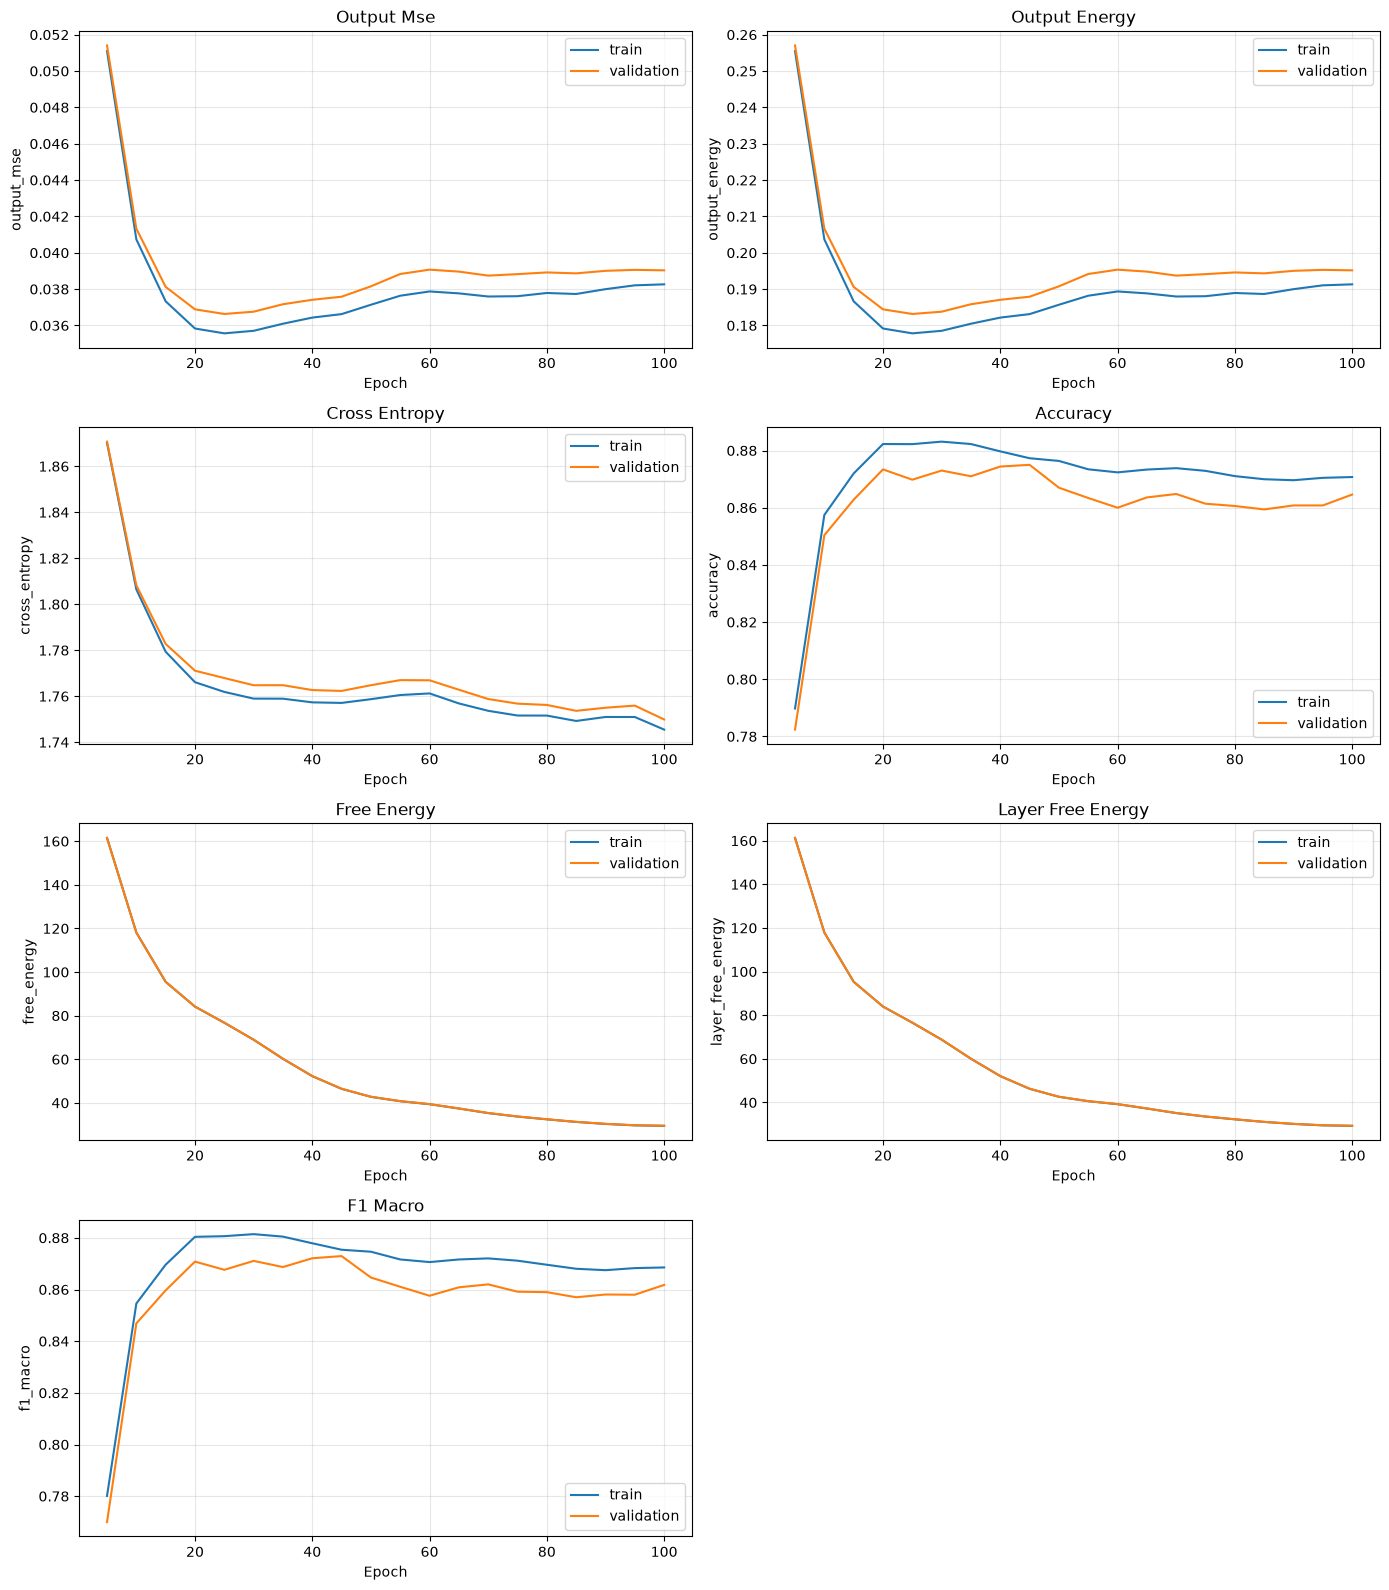

beste Validation-F1 (macro) 0.8729 bei Epoche 45


In [5]:
mnist_train_history = pd.DataFrame(mnist_history["train"], index=mnist_history["epoch"])
mnist_val_hist = pd.DataFrame(mnist_history["validation"], index=mnist_history["epoch"])

metrics = [c for c in mnist_train_history.columns if c != "n"]
n_plots = len(metrics)
n_cols = 2
n_rows = ceil(n_plots / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = np.array(axes).ravel()

for i, metric in enumerate(metrics):
	axes[i].plot(mnist_train_history[metric], label="train", color="tab:blue")
	if not mnist_val_hist.empty and metric in mnist_val_hist.columns:
		axes[i].plot(mnist_val_hist[metric], label="validation", color="tab:orange")
	axes[i].set_title(metric.replace("_", " ").title())
	axes[i].set_xlabel("Epoch")
	axes[i].set_ylabel(metric)
	axes[i].legend()
	axes[i].grid(True, alpha=0.3)

for j in range(i + 1, len(axes)):
	axes[j].axis("off")

plt.tight_layout()
plt.show()

best = mnist_val_hist["f1_macro"].idxmax()
print(f"beste Validation-F1 (macro) {mnist_val_hist['f1_macro'].max():.4f} bei Epoche {best}")


In [10]:
mnist_train_history[metric].sort_values(ascending=False).head(10)

30    0.881437
25    0.880649
35    0.880477
20    0.880399
40    0.877904
45    0.875400
50    0.874634
70    0.872051
55    0.871639
65    0.871632
Name: f1_macro, dtype: float64

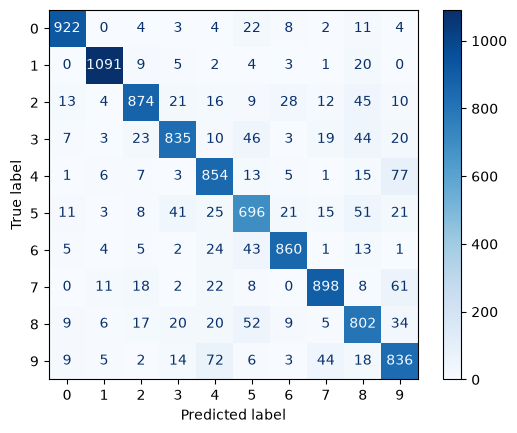

In [6]:
cm = confusion_matrix(y_test_MNIST, predicted_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(MNIST_num_classes)))
disp.plot(cmap=plt.cm.Blues)
plt.show()

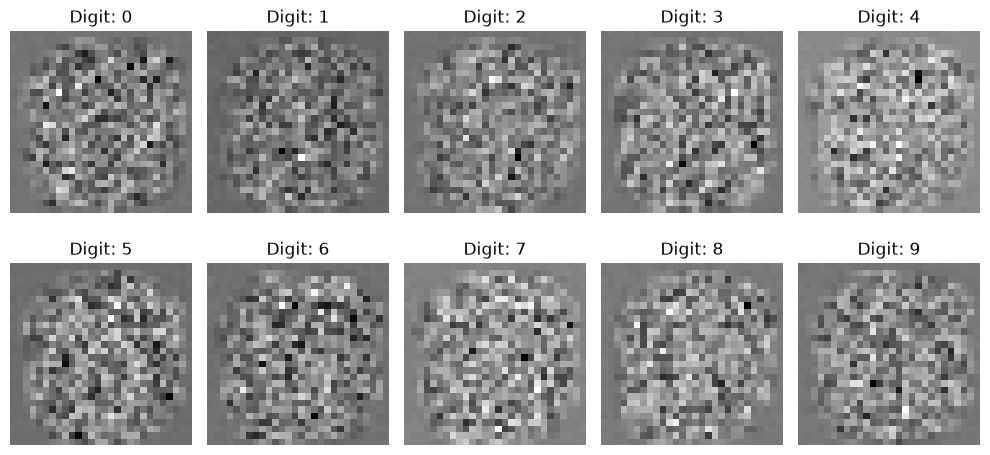

In [7]:
fig = plt.figure(figsize=(10, 5))

for digit in range(10):
    image = pcn_mnist.run(mode="generative", y=digit, eta_infer=0.1, T_infer=100)
    
    image_2d = image.input_state.view(28, 28)
    
    plt.subplot(2, 5, digit + 1)
    
    plt.imshow(image_2d.cpu().numpy(), cmap='gray')
    plt.title(f"Digit: {digit}")
    plt.axis('off')  # Blendet die Achsen aus

plt.tight_layout()
plt.show()


100%|██████████| 10/10 [00:23<00:00,  2.37s/it]


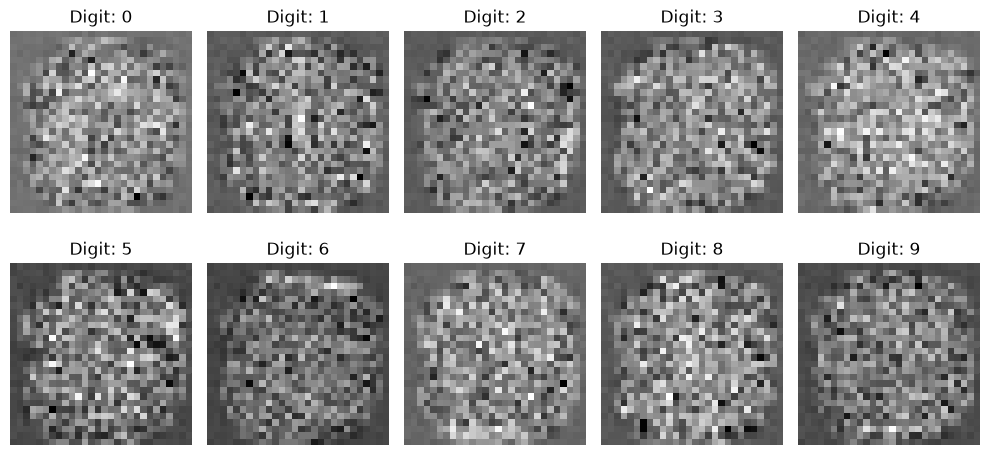

In [8]:
fig = plt.figure(figsize=(10, 5))
n = 100 
mnist_device = next(pcn_mnist.parameters()).device

for digit in tqdm(range(10)):
    image_sum = torch.zeros((28, 28), device=mnist_device)
    for _ in range(n):
        image = pcn_mnist.run(mode="generative", y=digit, eta_infer=0.1, T_infer=100)
        image_sum += image.input_state.view(28, 28)

    image_2d = image_sum / n

    plt.subplot(2, 5, digit + 1)

    plt.imshow(image_2d.cpu().numpy(), cmap='gray')
    plt.title(f"Digit: {digit}")
    plt.axis('off')  # Blendet die Achsen aus

plt.tight_layout()
plt.show()